Homework 10, problem 2, part c

In [2]:
# libraries and paramters

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import poisson

lam = 12
mu = 3
T = 500
np.random.seed(42)

In [3]:
# initial state
n = 0
t = 0
time_in_state = {}

while t < T:

    rate = lam + n * mu
    dt = np.random.exponential(1 / rate)

    if t + dt > T:
        dt = T - t

        time_in_state[n] = time_in_state.get(n, 0) + dt
        t = T
        break

    time_in_state[n] = time_in_state.get(n, 0) + dt # time spent in current state
    t += dt

    if np.random.random() < (lam / rate): # arrival or departure
        n += 1
    else:
        n -= 1

In [4]:
max_state = max(time_in_state.keys())
states = np.arange(max_state + 1)

empirical = np.array([time_in_state.get(i, 0) / T for i in states])

# Poisson(4)
theoretical = poisson.pmf(states, mu=4)

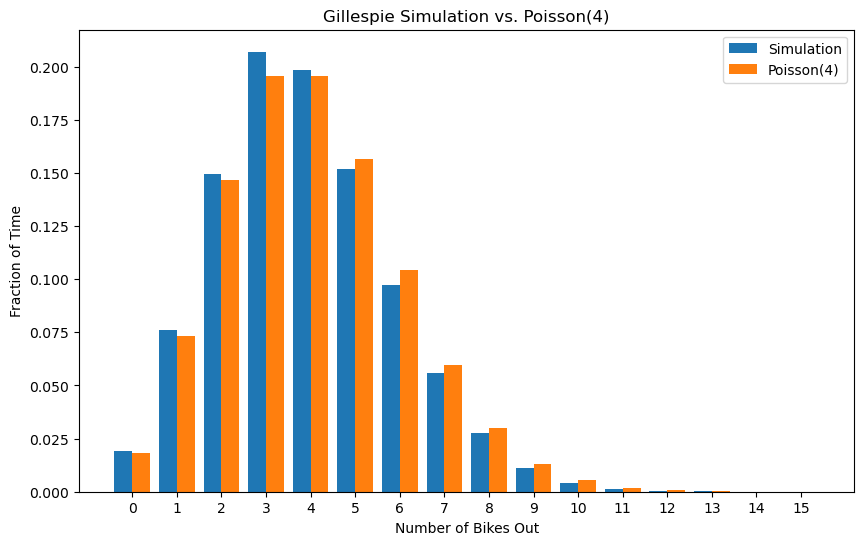

In [5]:
plt.figure(figsize=(10, 6))

width = 0.4

plt.bar(states - width/2, empirical, width, label = "Simulation")
plt.bar(states + width/2, theoretical, width, label = "Poisson(4)")

plt.xlabel("Number of Bikes Out")
plt.ylabel("Fraction of Time")
plt.title("Gillespie Simulation vs. Poisson(4)")
plt.legend()
plt.xticks(states)
plt.show()

In [8]:
differences = np.abs(empirical - theoretical)

largest_difference = np.max(differences)
largest_state = np.argmax(differences)

print("Largest difference:", largest_difference)
print("State with largest difference:", largest_state)

time_average = sum(n * time_spent for n, time_spent in time_in_state.items()) / T

print("Simulated time average:", time_average)
print("Theoretical mean:", 4)

c = 0
while poisson.sf(c, mu=4) > 0.01:
    c += 1

print("Smallest fleet size:", c)
print("Probability of exceeding fleet:",
      poisson.sf(c, mu=4))

Largest difference: 0.011593081279996309
State with largest difference: 3
Simulated time average: 3.9122356430415395
Theoretical mean: 4
Smallest fleet size: 9
Probability of exceeding fleet: 0.008132242796933871
